In [3]:
import pandas as pd
import numpy as np
import seaborn as sns

In [19]:
data = pd.read_csv('imbalanced_dataset_1000_rows.csv')

In [20]:
data

,Feature_1,Feature_2,Target
0,52.52,3.64,0
1,46.29,5.01,0
2,49.70,5.98,1
3,34.00,5.60,0
4,59.17,7.31,1
...,...,...,...
995,65.37,9.44,1
996,67.16,9.25,1
997,39.14,4.87,0
998,47.68,3.70,0


In [21]:
data.isna().sum()

Feature_1    0
Feature_2    0
Target       0
dtype: int64

In [22]:
data.Target.value_counts()

Target
1    900
0    100
Name: count, dtype: int64

In [27]:
data_feature_1 = data[data['Target']==0]
data_feature_2 = data[data['Target']==1]

In [31]:
data_feature_2.value_counts().sum()

np.int64(900)

UPSACLING

In [33]:
from sklearn.utils import resample
upscaled_minority = resample(data_feature_1,replace=True,n_samples=len(data_feature_2))

In [34]:
upscaled_minority

,Feature_1,Feature_2,Target
751,39.64,2.45,0
221,28.74,5.44,0
475,48.24,4.89,0
221,28.74,5.44,0
998,47.68,3.70,0
...,...,...,...
692,51.52,4.70,0
712,33.99,2.67,0
406,41.91,5.27,0
873,50.42,5.44,0


In [44]:
down_scaled_majority = resample(data_feature_2,replace=False,n_samples=len(data_feature_1))

In [45]:
down_scaled_majority

,Feature_1,Feature_2,Target
689,61.21,8.36,1
958,100.00,10.38,1
229,64.82,8.28,1
598,79.29,6.71,1
922,84.28,9.29,1
...,...,...,...
535,79.00,5.64,1
432,62.85,10.48,1
222,72.71,8.61,1
6,69.02,7.15,1


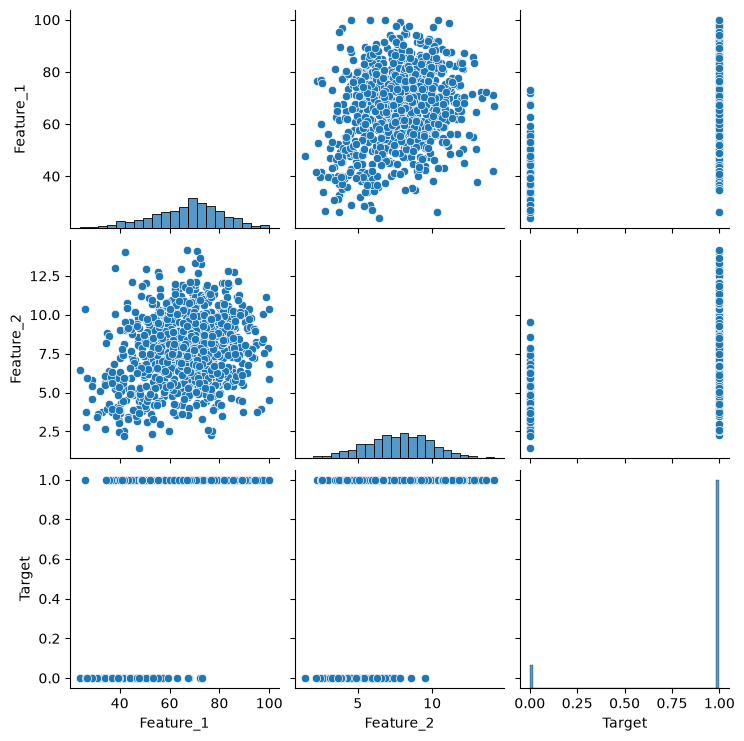

In [40]:
sns.pairplot(data=data)

In [46]:
df1 = pd.concat([data_feature_1,down_scaled_majority])

In [47]:
df1

,Feature_1,Feature_2,Target
0,52.52,3.64,0
1,46.29,5.01,0
3,34.00,5.60,0
11,38.01,5.21,0
13,29.02,5.79,0
...,...,...,...
535,79.00,5.64,1
432,62.85,10.48,1
222,72.71,8.61,1
6,69.02,7.15,1


In [52]:
df1.Target.value_counts()

Target
0    100
1    100
Name: count, dtype: int64

In [48]:
df2 = pd.concat([data_feature_2,upscaled_minority])

In [49]:
df2

,Feature_1,Feature_2,Target
2,49.70,5.98,1
4,59.17,7.31,1
5,65.89,5.14,1
6,69.02,7.15,1
7,49.53,8.24,1
...,...,...,...
692,51.52,4.70,0
712,33.99,2.67,0
406,41.91,5.27,0
873,50.42,5.44,0


In [50]:
df2.Target.value_counts()

Target
1    900
0    900
Name: count, dtype: int64

In [1]:
from sklearn.datasets import make_classification
x,y = make_classification(n_samples=1000,n_redundant=0,n_features=2,n_clusters_per_class=1,weights=[0.90],random_state=12)

In [4]:
mdf = pd.DataFrame(x,columns=['f1','f2'])
mdf2 = pd.DataFrame(y,columns=['target'])


In [5]:
df3 = pd.concat([mdf,mdf2],axis=1)

In [6]:
df3

,f1,f2,target
0,-0.762898,-0.706808,0
1,-1.075436,-1.051162,0
2,-0.610115,-0.909802,0
3,-2.023284,-0.428945,1
4,-0.812921,-1.316206,0
...,...,...,...
995,-0.712495,-0.880452,0
996,-2.625830,-2.827891,0
997,-1.326439,-1.815178,0
998,-0.833486,-0.514647,0


In [7]:
df3.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   f1      1000 non-null   float64
 1   f2      1000 non-null   float64
 2   target  1000 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 23.6 KB


In [9]:
df3.isnull().sum()

f1        0
f2        0
target    0
dtype: int64

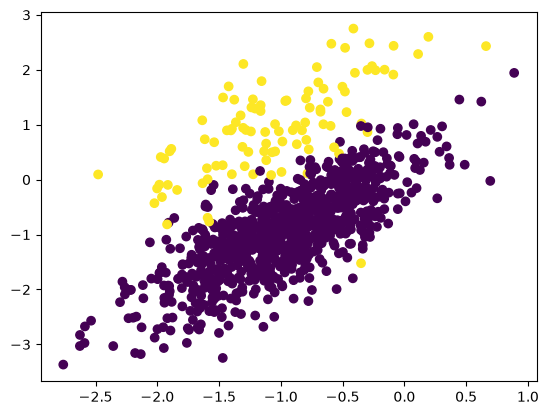

In [10]:
import matplotlib.pyplot as plt
plt.scatter(df3['f1'],df3['f2'], c=df3['target'])

In [16]:
!pip install imblearn
from imblearn.oversampling import SMOTE

ModuleNotFoundError: No module named 'imblearn'

In [15]:
from imblearn.oversampling import SMOTE

ModuleNotFoundError: No module named 'imblearn'